In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

For this exercise, I will use this dataset to build a classification model that predicts the target variable, y. I started by importing the dataset into a Pandas DataFrame. I wanted to look at the first few rows to get a better idea of how the data is organized and what types of values each column contains.

In [2]:
#load the dataset
df = pd.read_csv("eda_classification.csv")

df.head()


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,Jun,6.559220,-14.452810,-4.732855,0.381673,2.563194,"($1,306.52)",-89.394348,-28.454044,-16.201298,-0.01%,0.217010,tesla,thurday,9.729891,-0.786431,small,1
1,-37.214754,July,10.774930,-15.384004,-0.077339,10.983774,-15.210206,($24.86),153.032652,-32.557736,69.675903,0.00%,-3.584908,Toyota,thur,35.727926,-0.985552,small,0
2,0.330441,Aug,-19.609972,-9.167911,2.064124,12.071688,12.506141,($110.85),-141.437276,-20.794952,55.042604,0.00%,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,Aug,-8.011390,6.759264,1.727615,-1.768382,24.039733,($324.43),51.039653,-7.046908,-31.424419,0.01%,7.908897,Toyota,wed,-2.891882,-2.690222,small,0
4,-4.202598,May,7.076210,-26.004919,-4.269696,-3.414224,2.115989,"$1,213.37",-31.046700,19.061182,-31.525515,-0.01%,0.846719,Honda,wednesday,25.497480,3.516801,small,1


Next, I wanted to look at the overall structure of the dataset. This should help me identify which variables are numerical and which ones might need to be cleaned up before building the model.

In [3]:
# Reviewe number of rows and columns
print("Dataset shape:", df.shape)

# Review column names
print("\nColumn names:")
print(df.columns.tolist())

# Review data types
print("\nDataset information:")
df.info()


Dataset shape: (9999, 19)

Column names:
['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x0      9996 non-null   float64
 1   x1      9999 non-null   object 
 2   x2      9995 non-null   float64
 3   x3      9996 non-null   float64
 4   x4      9997 non-null   float64
 5   x5      9997 non-null   float64
 6   x6      9999 non-null   float64
 7   x7      9996 non-null   object 
 8   x8      9998 non-null   float64
 9   x9      9999 non-null   float64
 10  x10     9996 non-null   float64
 11  x11     9997 non-null   object 
 12  x12     9995 non-null   float64
 13  x13     9998 non-null   object 
 14  x14     9997 non-null   object 
 15  x15     9999 non-null   float64
 16  x16     9998 non-null   float64
 17  

In [4]:
#Descriptive statistics for numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
x0,9996.0,6.501091,29.140034,-106.809919,-13.094564,6.659263,26.214107,114.823451
x2,9995.0,-3.729880,17.237178,-65.137848,-15.356197,-3.825630,7.764036,67.685933
x3,9996.0,-7.335819,38.355015,-150.846091,-33.079854,-7.374468,18.477979,127.204103
x4,9997.0,-0.001323,3.995307,-14.616540,-2.681308,0.010637,2.635699,16.923269
x5,9997.0,1.347141,9.606695,-37.499530,-5.047927,1.217076,7.807128,38.624213
x6,9999.0,1.214413,17.352962,-59.900503,-10.904697,0.814006,12.693538,68.865261
x8,9998.0,-4.239862,131.921984,-661.764937,-91.489340,-4.744892,83.831778,476.910533
x9,9999.0,-0.297257,37.987287,-142.719688,-25.685742,-0.239779,25.459537,181.063340
x10,9996.0,-22.482050,91.723733,-427.412374,-79.734745,-20.459860,38.383398,319.592518
x12,9995.0,0.034517,6.065264,-25.024464,-4.191568,0.154775,4.136013,21.540626


Before starting on the model, I checked for missing values and duplicates. The descriptive statistics showed that the dataset has 9,999 rows and 19 columns. Also, from looking at the descriptive statistics, I noticed that some numerical values have pretty large ranges, like x8 going from about -661.76 to 476.91, and several columns have fewer than 9,999 non-null values, meaning there are some missing values I'll need to look into before starting the model.

In [5]:
#Check missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
y      0
dtype: int64

Total missing values: 31


In [6]:
#Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


There are no duplicate rows, but this does show me there are 31 missing values. 

In [7]:
#Target distribution
#Count each target value
print(df["y"].value_counts(dropna=False))

#Percentage of each class
print("\nTarget percentages:")
print(df["y"].value_counts(normalize=True) * 100)

y
0    5080
1    4919
Name: count, dtype: int64

Target percentages:
y
0    50.805081
1    49.194919
Name: proportion, dtype: float64


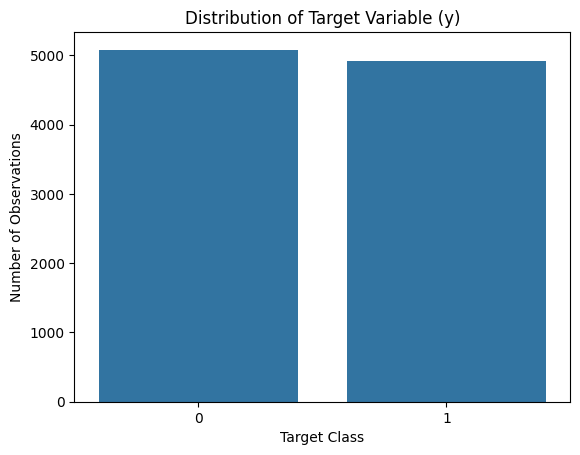

In [8]:
#Plot the target distribution
sns.countplot(data=df, x="y")
plt.title("Distribution of Target Variable (y)")
plt.xlabel("Target Class")
plt.ylabel("Number of Observations")
plt.show()

After looking at the target variable y, I noticed that the two classes are pretty evenly split, with 50.81% being 0 and 49.19% being 1. I want to take a look at the categorical variables to see what kind of values they have and if anything needs to be cleaned up before moving on to the model.

In [9]:
#Identify categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

#Review unique values and their counts
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Categorical columns: ['x1', 'x7', 'x11', 'x13', 'x14', 'x17']

Column: x1
x1
July       2709
Jun        2357
Aug        2059
May        1144
sept.       912
Apr         413
Oct         246
Mar         116
Nov          27
Feb          10
Dev           5
January       1
Name: count, dtype: int64

Column: x7
x7
($243.22)     3
NaN           3
$1,732.87     2
($432.40)     2
($35.66)      2
             ..
($660.27)     1
($836.02)     1
$91.38        1
$1,514.51     1
($863.61)     1
Name: count, Length: 9850, dtype: int64

Column: x11
x11
0.00%     3914
-0.01%    2409
0.01%     2361
0.02%      581
-0.02%     579
0.03%       73
-0.03%      72
-0.04%       4
0.04%        4
NaN          2
Name: count, dtype: int64

Column: x13
x13
volkswagon    3132
Toyota        2773
bmw           1837
Honda         1277
tesla          545
chrystler      291
nissan          90
ford            39
mercades        11
chevrolet        3
NaN              1
Name: count, dtype: int64

Column: x14
x14
wed         

After looking at the categorical columns, I noticed that some values are written differently even though they mean the same thing, like abbreviations for months or weekdays. I also noticed that some numbers are being treated as text because they include dollar signs or percentages. Next, I wanted to look at the numerical variables a little closer to see how their values are spread out and whether there are any unusual patterns.

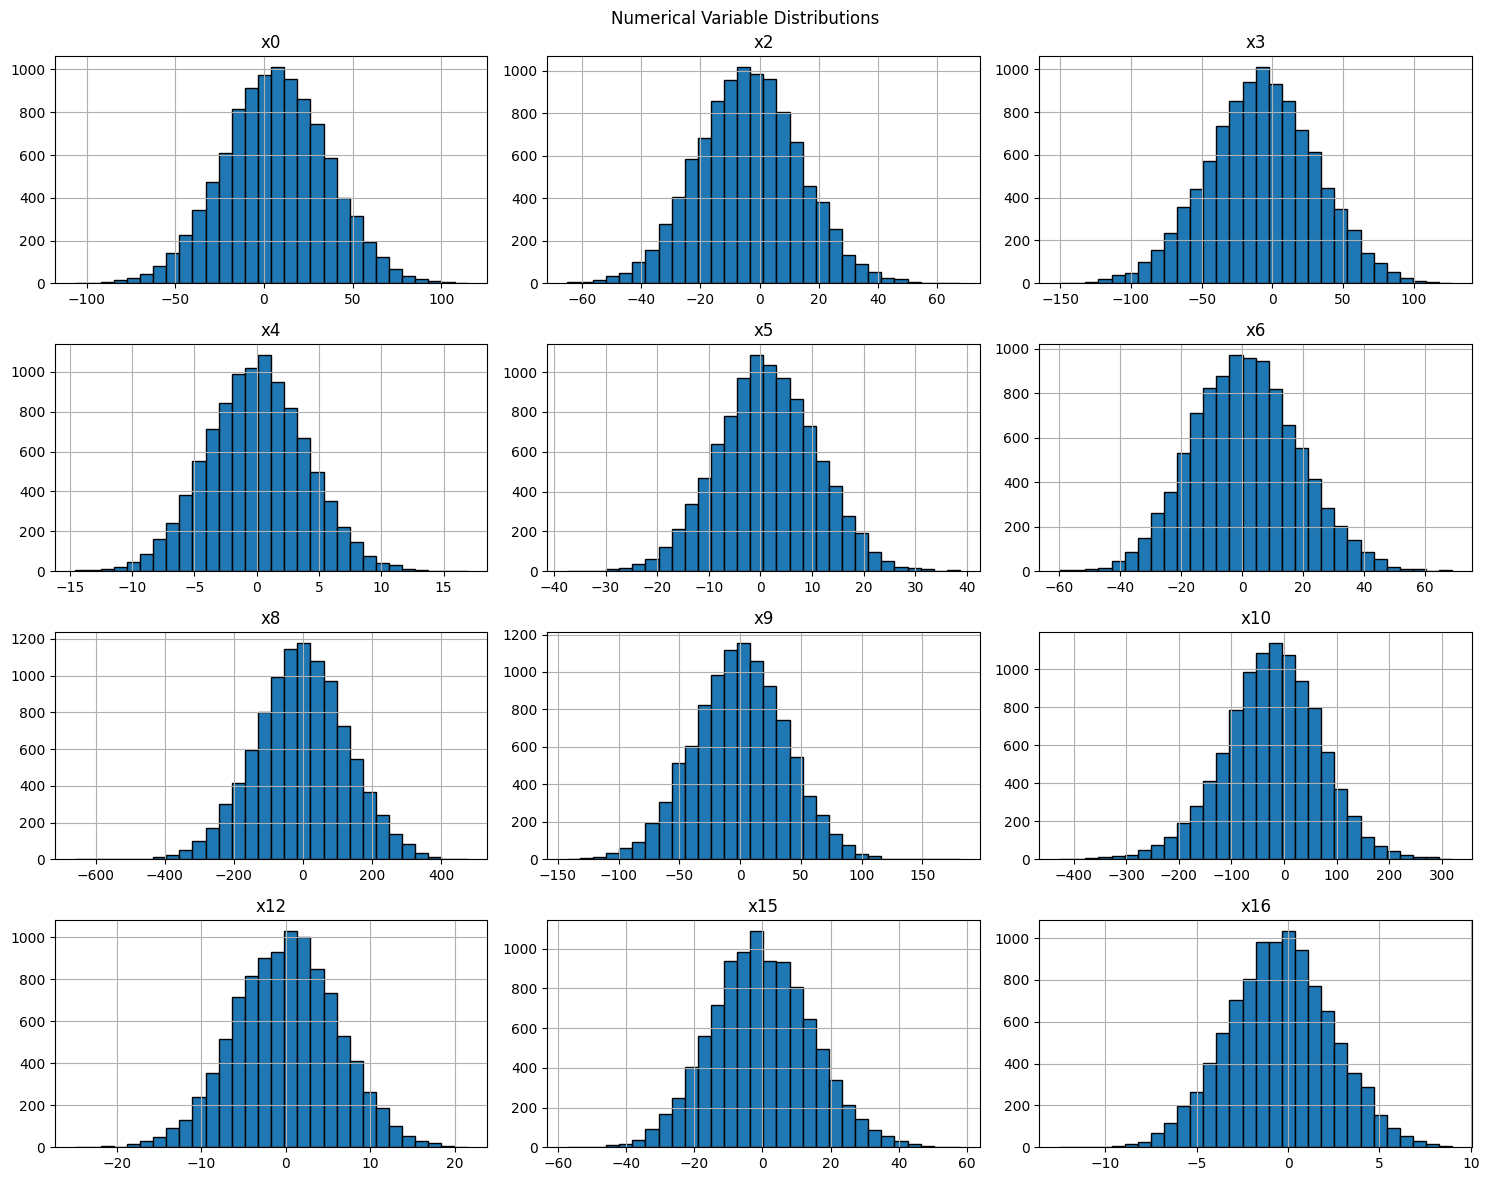

In [10]:
#Numerical Distribution
#Select numerical columns, excluding y
numeric_cols = df.select_dtypes(
    include="number"
).columns.drop("y").tolist()

#Create histograms
df[numeric_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Variable Distributions")
plt.tight_layout()
plt.show()

I found a few things that need to be cleaned up before building the model. Some columns have currency amounts or percentages that are being read as text, and others have inconsistent abbreviations or spelling. Fixing these will make the data more consistent and then it can actually be used by the classification model.

In [11]:
#Create a copy
df_clean = df.copy()

#Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

In [12]:
#Check the copy
df_clean.head()

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,Jun,6.559220,-14.452810,-4.732855,0.381673,2.563194,"($1,306.52)",-89.394348,-28.454044,-16.201298,-0.01%,0.217010,tesla,thurday,9.729891,-0.786431,small,1
1,-37.214754,July,10.774930,-15.384004,-0.077339,10.983774,-15.210206,($24.86),153.032652,-32.557736,69.675903,0.00%,-3.584908,Toyota,thur,35.727926,-0.985552,small,0
2,0.330441,Aug,-19.609972,-9.167911,2.064124,12.071688,12.506141,($110.85),-141.437276,-20.794952,55.042604,0.00%,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,Aug,-8.011390,6.759264,1.727615,-1.768382,24.039733,($324.43),51.039653,-7.046908,-31.424419,0.01%,7.908897,Toyota,wed,-2.891882,-2.690222,small,0
4,-4.202598,May,7.076210,-26.004919,-4.269696,-3.414224,2.115989,"$1,213.37",-31.046700,19.061182,-31.525515,-0.01%,0.846719,Honda,wednesday,25.497480,3.516801,small,1


Instead of modfying the original dataframe, I named the copy df_clean and modified the copy instead. 

In [13]:
# Review column x7
# Convert x7 currency amounts to numbers
currency = df_clean["x7"].astype("string").str.strip()

# Identify negative amounts in parentheses
negative = currency.str.startswith("(").fillna(False)

# Remove dollar signs, commas, and parentheses
currency = currency.str.replace(
    r"[$,()\s]", "", regex=True
)

# Convert to numerical values
df_clean["x7"] = pd.to_numeric(
    currency, errors="coerce"
)

# Keep negative amounts
df_clean.loc[negative, "x7"] = (
    -df_clean.loc[negative, "x7"].abs()
)

df_clean["x7"].head(10)


0   -1306.52
1     -24.86
2    -110.85
3    -324.43
4    1213.37
5   -1508.42
6   -1431.44
7    1613.55
8    1178.11
9    -312.04
Name: x7, dtype: Float64

For x7, I noticed that the values included dollar signs, commas, and parentheses, which caused Python to read them as text instead of numbers. I removed the extra formatting and converted the values into numerical data while keeping the negative amounts negative. This should make the column easier to work with when building the classification model.

In [14]:
#Cleaning percentages on x11
#Remove percentage signs and extra spaces
percent = (
    df_clean["x11"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
)

#Convert percentages into decimals
df_clean["x11"] = (
    pd.to_numeric(percent, errors="coerce") / 100
)

#Display the first 10 cleaned values
df_clean["x11"].head(10)


0   -0.0001
1       0.0
2       0.0
3    0.0001
4   -0.0001
5       0.0
6    0.0001
7    0.0001
8       0.0
9       0.0
Name: x11, dtype: Float64

Similar to x7, I noticed that x11 had percentage signs, which caused Python to treat the values as text. I removed the percentage signs and converted everything into decimals so the model can recognize them as numerical values.

In [15]:
#Standardize
#Identify remaining categorical columns
category_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns.tolist()

#Convert to lowercase and remove extra spaces
for col in category_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

#Standardize month names
month_map = {
    "jan": "january",
    "feb": "february",
    "mar": "march",
    "apr": "april",
    "jun": "june",
    "jul": "july",
    "aug": "august",
    "sep": "september",
    "sept": "september",
    "sept.": "september",
    "oct": "october",
    "nov": "november",
    "dec": "december"
}

df_clean["x1"] = df_clean["x1"].replace(month_map)

#Standardize weekday names
day_map = {
    "mon": "monday",
    "tue": "tuesday",
    "tues": "tuesday",
    "wed": "wednesday",
    "weds": "wednesday",
    "thur": "thursday",
    "thurs": "thursday",
    "thurday": "thursday",
    "fri": "friday",
    "sat": "saturday",
    "sun": "sunday"
}

df_clean["x14"] = df_clean["x14"].replace(day_map)

#Standardize car brand spelling
df_clean["x13"] = df_clean["x13"].replace({
    "volkswagon": "volkswagen",
    "chrystler": "chrysler"
})

#Review the cleaned categories
for col in category_cols:
    print(f"\nColumn: {col}")
    print(df_clean[col].value_counts(dropna=False))



Column: x1
x1
july         2709
june         2357
august       2059
may          1144
september     912
april         413
october       246
march         116
november       27
february       10
dev             5
january         1
Name: count, dtype: Int64

Column: x13
x13
volkswagen    3132
toyota        2773
bmw           1837
honda         1277
tesla          545
chrysler       291
nissan          90
ford            39
mercades        11
chevrolet        3
<NA>             1
Name: count, dtype: Int64

Column: x14
x14
wednesday    5198
thursday     4433
tuesday       214
friday        137
monday         15
<NA>            2
Name: count, dtype: Int64

Column: x17
x17
small     8849
medium     783
large      367
Name: count, dtype: Int64


I cleaned up the categorical variables because some of the values were written differently. For example, some months and weekdays were abbreviated, and a few categories had spelling differences. I converted everything to lowercase and standardized the names so they would be treated as the same category instead of separate ones.

In [16]:
#Review updated data types
print("Updated data types:")
print(df_clean.dtypes)

#Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

#Compare missing values before and after cleaning
print("\nChange in missing values:")
print(
    df_clean.isnull().sum() - df.isnull().sum()
)

#Display first five rows
df_clean.head()

Updated data types:
x0            float64
x1     string[python]
x2            float64
x3            float64
x4            float64
x5            float64
x6            float64
x7            Float64
x8            float64
x9            float64
x10           float64
x11           Float64
x12           float64
x13    string[python]
x14    string[python]
x15           float64
x16           float64
x17    string[python]
y               int64
dtype: object

Missing values after cleaning:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
y      0
dtype: int64

Change in missing values:
x0     0
x1     0
x2     0
x3     0
x4     0
x5     0
x6     0
x7     0
x8     0
x9     0
x10    0
x11    0
x12    0
x13    0
x14    0
x15    0
x16    0
x17    0
y      0
dtype: int64


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
0,-17.933519,june,6.559220,-14.452810,-4.732855,0.381673,2.563194,-1306.52,-89.394348,-28.454044,-16.201298,-0.0001,0.217010,tesla,thursday,9.729891,-0.786431,small,1
1,-37.214754,july,10.774930,-15.384004,-0.077339,10.983774,-15.210206,-24.86,153.032652,-32.557736,69.675903,0.0,-3.584908,toyota,thursday,35.727926,-0.985552,small,0
2,0.330441,august,-19.609972,-9.167911,2.064124,12.071688,12.506141,-110.85,-141.437276,-20.794952,55.042604,0.0,-3.991366,bmw,wednesday,-9.283523,-3.394718,small,1
3,-13.709765,august,-8.011390,6.759264,1.727615,-1.768382,24.039733,-324.43,51.039653,-7.046908,-31.424419,0.0001,7.908897,toyota,wednesday,-2.891882,-2.690222,small,0
4,-4.202598,may,7.076210,-26.004919,-4.269696,-3.414224,2.115989,1213.37,-31.046700,19.061182,-31.525515,-0.0001,0.846719,honda,wednesday,25.497480,3.516801,small,1


After cleaning the data, I checked the column types and missing values again to make sure everything worked. Both x7 and x11 are now numerical and the cleaning didn't create any new missing values. There are still a few missing values in some columns but I'll handle those during preprocessing instead of removing the rows.

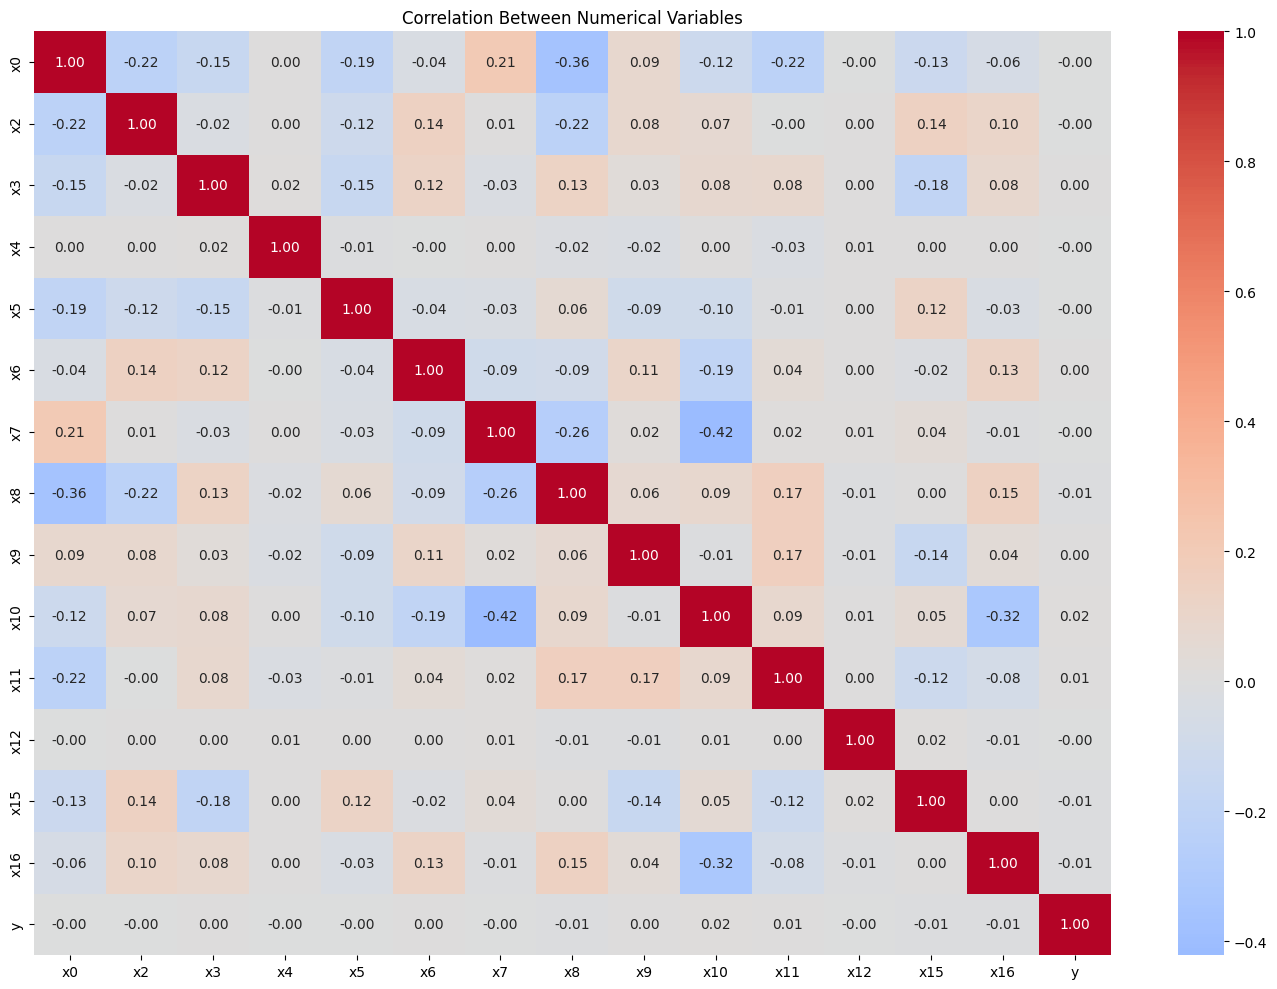

In [17]:
#Checking correlations
#Select numerical columns
numerical_data = df_clean.select_dtypes(
    include="number"
)

#Calculate correlations
correlation_matrix = numerical_data.corr()

#Create correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()


I used a correlation heatmap to see how the numerical variables relate to each other and to the target variable, y. I wanted to get a better idea of whether any features have stronger positive or negative relationships that could help with the classification model.

In [18]:
#Separate the predictor variables from the target
X = df_clean.drop(columns=["y"]).copy()
y = df_clean["y"]

#Check target values
print("Target values:", y.unique())

#Review dataset shapes
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Target values: [1 0]
Predictor shape: (9999, 18)
Target shape: (9999,)


I've finished cleaning and exploring the data, I separated the predictors from the target variable. X contains the 18 features the model will use to make predictions, while y contains the actual 0 or 1 outcomes. This will help me prepare everything for training and testing.

In [19]:
#Identify categorical columns
cat_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

#Convert categorical columns to object type
#use np.nan for missing values
for col in cat_cols:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(
        X[col].notna(), np.nan
    )

#Display categorical columns
print("Categorical columns:", cat_cols)

#Check missing values
print("\nMissing values in predictors:")
print(X.isnull().sum())


Categorical columns: ['x1', 'x13', 'x14', 'x17']

Missing values in predictors:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
dtype: int64


I also made sure the categorical columns were in a format that Scikit-learn could work with. Since there are still a few missing values in the dataset, I'm keeping track of those so they can be filled in during preprocessing. This way, I don't have to delete rows just because they're missing a small amount of information.

In [20]:
#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Review the sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

#Check the target distribution
print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target percentages:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (7999, 18)
Testing data: (2000, 18)

Training target percentages:
y
0    50.806351
1    49.193649
Name: proportion, dtype: float64

Testing target percentages:
y
0    50.8
1    49.2
Name: proportion, dtype: float64


I split the data into 80% for training and 20% for testing, which gave me 7,999 rows for training and 2,000 for testing. I also used stratification since the original target was almost evenly split between 0 and 1. This helps keep both classes fairly equal when training and testing the model.

In [21]:
#Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

#Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

#Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")


Numerical features: ['x0', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x15', 'x16']
Categorical features: ['x1', 'x13', 'x14', 'x17']

Preprocessing pipeline created successfully!


Since the dataset has both numerical and categorical variables, I needed to prepare them differently before training the model. I set up one-hot encoding for the categorical columns and standardization for the numerical ones since their values have pretty different ranges. I also filled in the remaining missing values with the median.

In [22]:
#Create the logistic regression model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

#Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Now that the features are prepared, I trained a logistic regression model to predict y. I chose logistic regression because the target is binary.

In [23]:
#Make predictions using the testing data
y_pred = model.predict(X_test)

#Compare predictions to actual values
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

#Check whether the prediction was correct
results["Correct"] = (
    results["Actual"] == results["Predicted"]
)

#Display the first 15 predictions
results.head(15)

,Actual,Predicted,Correct
0,0,0,True
1,0,0,True
2,0,0,True
3,0,0,True
4,1,0,False
5,1,0,False
6,0,0,True
7,1,1,True
8,0,1,False
9,0,1,False


After training the model, I compared the predicted values with the actual values of y to see how well it performed. Looking at the first 15 predictions, the model got 10 correct and 5 incorrect. I want to check the overall accuracy to get a better idea of how well the model performed on the entire testing dataset.

In [24]:
#Evaluate model
#Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

#Display the classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Model Accuracy: 51.60%

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.60      0.56      1016
           1       0.51      0.43      0.47       984

    accuracy                           0.52      2000
   macro avg       0.52      0.51      0.51      2000
weighted avg       0.52      0.52      0.51      2000



After checking the model's performance, I found that it had an overall accuracy of 51.60%, which is pretty low. Looking at the classification report, the model did a little better predicting 0, with a recall of 0.60 compared to 0.43 for 1. The F1-scores were also fairly low at 0.56 for 0 and 0.47 for 1. Overall, it looks like the model is struggling to identify both classes accurately, especially 1.

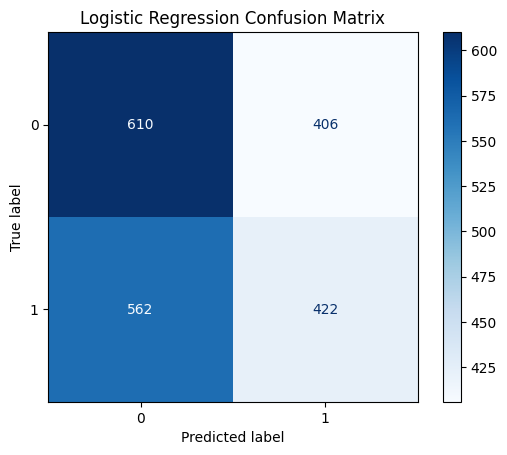

In [25]:
#Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

#Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

Looking at the confusion matrix, the model correctly predicted 610 values of 0 and 422 values of 1, but it also made quite a few mistakes. It incorrectly predicted 406 values as 1 and 562 values as 0, which shows that it struggled more with identifying class 1. This lines up with the 51.60% accuracy from the classification report and shows that the model isn't making very reliable predictions yet.

In [26]:
#Compare to Baseline
#Find the most common class in the training data
majority_class = y_train.mode()[0]

#Create baseline predictions
baseline_pred = np.full(
    len(y_test),
    majority_class
)

#Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

#Compare baseline and logistic regression
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")
print(f"Logistic Regression Accuracy: {accuracy:.2%}")

#Calculate the difference
improvement = (accuracy - baseline_accuracy) * 100

print(
    f"Accuracy Difference: "
    f"{improvement:.2f} percentage points"
)

Baseline Accuracy: 50.80%
Logistic Regression Accuracy: 51.60%
Accuracy Difference: 0.80 percentage points


I compared my logistic regression model to a baseline that always predicts the most common class. The baseline had an accuracy of 50.80%, while my logistic regression model reached 51.60%, which is only a 0.80 percentage point improvement. Although the model did slightly better, the difference is pretty small, which tells me it might not be finding many useful patterns in the data.